# Exploratory Data Analysis (EDA) - Industrial Anomaly Detection
This notebook explores the MetroPT-3 compressor dataset, performs statistical analysis, and visualizes trends and correlations.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('../data/MetroPT3(AirCompressor).csv', nrows=100000) # Load subset for EDA speed
if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df.set_index('timestamp', inplace=True)
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
df = df.drop_duplicates()

df.head()


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


## Summary Statistics


In [2]:
df.describe()


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.000000,99811.0,99811.0
mean,0.571126,8.970743,8.373029,-0.015484,8.973016,57.115831,1.312058,0.935668,0.064352,0.967879,0.935668,0.000010,0.999188,1.0,1.0
std,2.259186,0.555629,2.259997,0.097765,0.555070,3.379269,1.992941,0.245344,0.245379,0.176322,0.245344,0.003165,0.028476,0.0,0.0
min,-0.030000,7.324000,-0.030000,-0.028000,7.326000,31.975000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,1.0
25%,-0.012000,8.494000,8.390000,-0.020000,8.496000,55.300000,0.035000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.0,1.0
50%,-0.012000,8.948000,8.864000,-0.018000,8.950000,57.300000,0.037500,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.0,1.0
75%,-0.010000,9.424000,9.362000,-0.016000,9.428000,59.175000,3.717500,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.0,1.0
max,10.544000,10.164000,10.158000,6.530000,10.168000,69.150000,8.292500,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0


## Correlation Heatmap


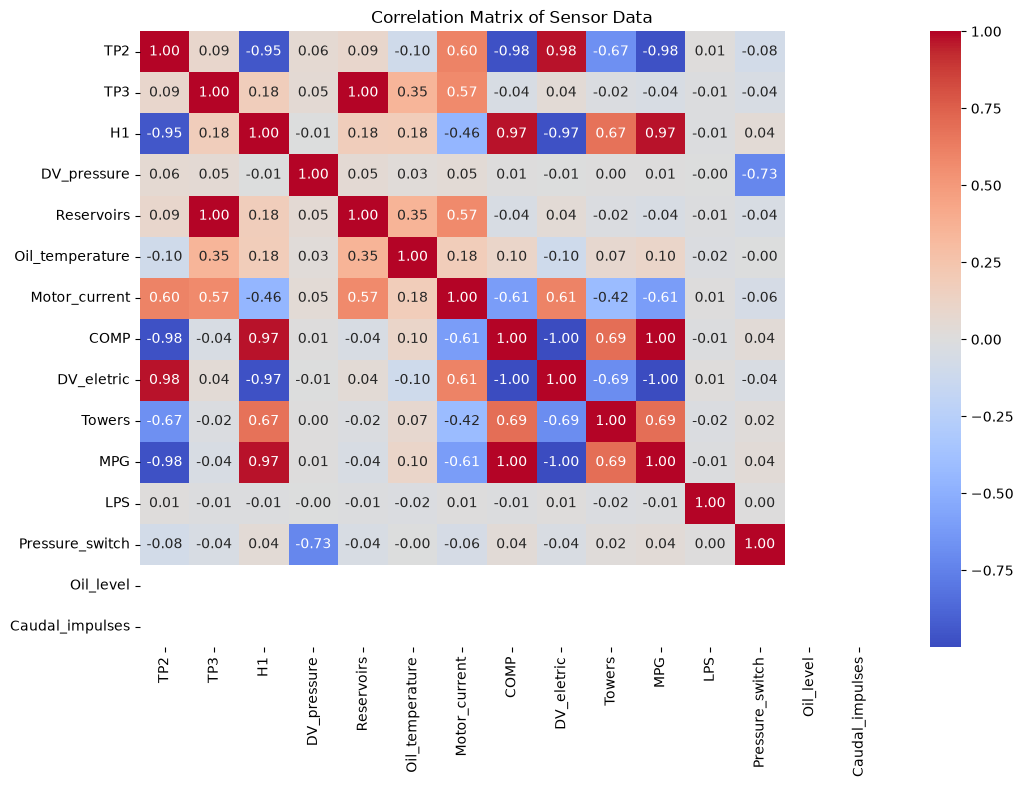

In [3]:
plt.figure(figsize=(12, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Sensor Data')
plt.show()


## Time-Series Trends


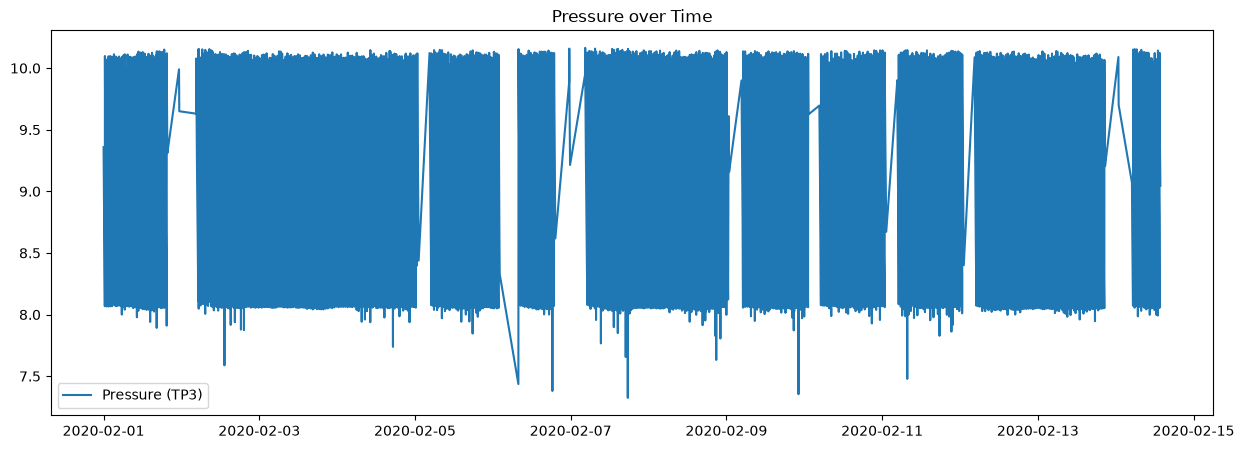

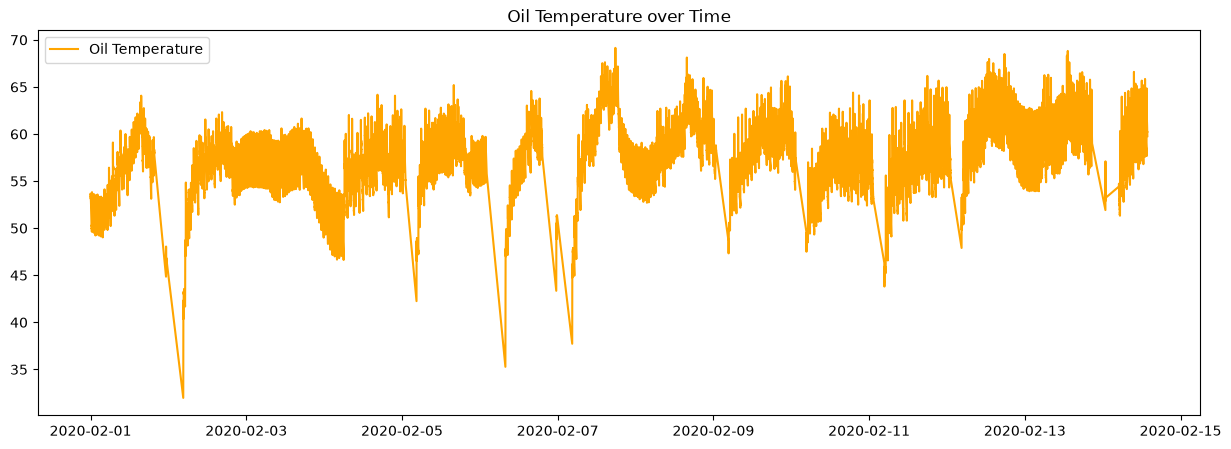

In [4]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['TP3'], label='Pressure (TP3)')
plt.title('Pressure over Time')
plt.legend()
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(df.index, df['Oil_temperature'], label='Oil Temperature', color='orange')
plt.title('Oil Temperature over Time')
plt.legend()
plt.show()


## Sensor Distributions


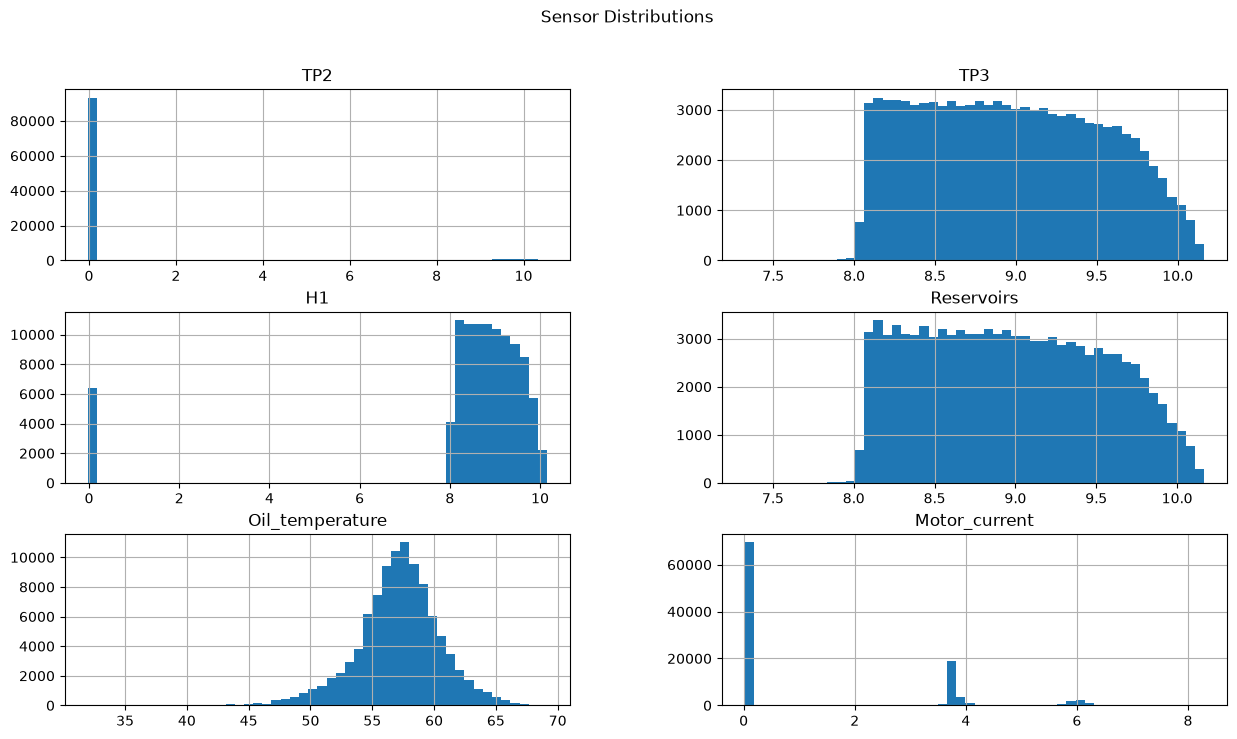

In [5]:
cols = ['TP2', 'TP3', 'H1', 'Reservoirs', 'Oil_temperature', 'Motor_current']
df[cols].hist(bins=50, figsize=(15, 8))
plt.suptitle('Sensor Distributions')
plt.show()


## Motor Current and Operating States


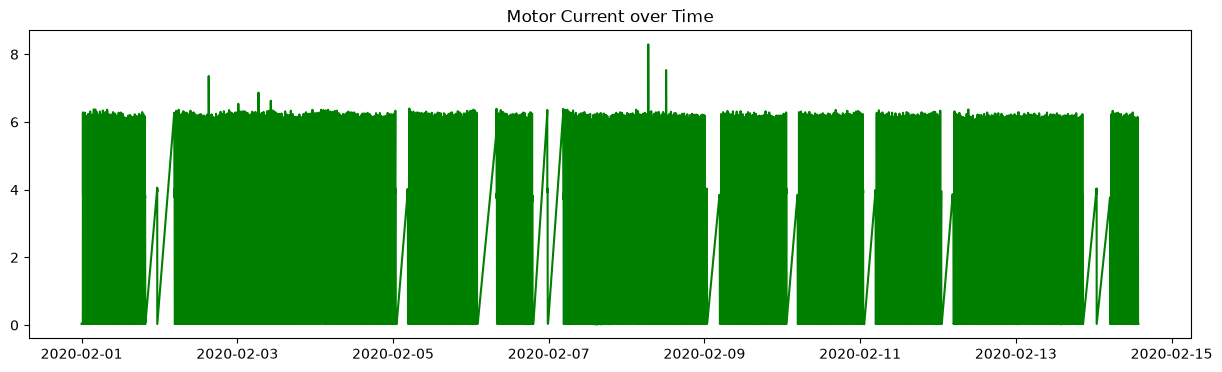

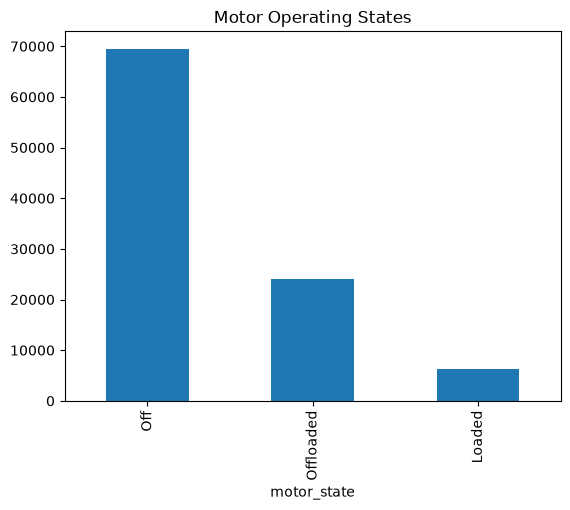

In [6]:
plt.figure(figsize=(15, 4))
plt.plot(df.index, df['Motor_current'], color='green')
plt.title('Motor Current over Time')
plt.show()

df['motor_state'] = pd.cut(df['Motor_current'], bins=[-1, 1, 5, 100], labels=['Off', 'Offloaded', 'Loaded'])
df['motor_state'].value_counts().plot(kind='bar', title='Motor Operating States')
plt.show()


## Hourly Pattern and Known Failure Windows


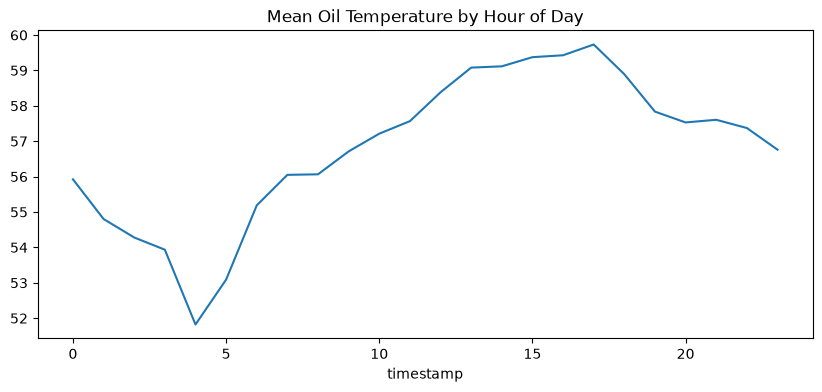

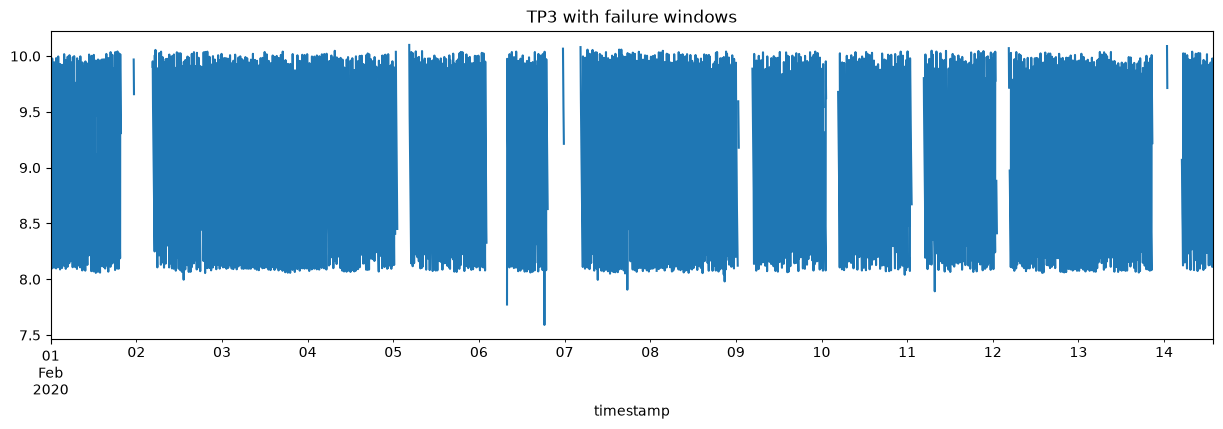

In [7]:
df.groupby(df.index.hour)['Oil_temperature'].mean().plot(figsize=(10, 4), title='Mean Oil Temperature by Hour of Day')
plt.show()

# Known air-leak failure windows (EDA reads only the first 100k rows, so most fall outside this sample;
# load the full file or raise nrows to see them)
windows = [('2020-04-18 00:00', '2020-04-18 23:59'), ('2020-05-29 23:30', '2020-05-30 06:00'),
           ('2020-06-05 10:00', '2020-06-07 14:30'), ('2020-07-15 14:30', '2020-07-15 19:00')]
ax = df['TP3'].resample('1min').mean().plot(figsize=(15, 4), title='TP3 with failure windows')
for start, end in windows:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='red', alpha=0.3)
plt.show()
